# Studi Komparatif Generative Models — Colab
**Vanilla AE · Sparse AE · VAE · Vanilla GAN · DCGAN · DDPM**

Notebook ini mendampingi draf laporan tugas Deep Learning D6421. Penjelasan dibuat ringkas,
sedangkan fungsi model dan evaluasi disusun terpisah agar mudah dipelajari.

**Cara mulai:** upload notebook ke Google Colab, pilih **Runtime → Change runtime type → GPU**,
lalu jalankan sel berurutan. Coba `PROFILE = "smoke"` terlebih dahulu. Untuk hasil tugas,
gunakan `PROFILE = "full"`, jalankan seluruh training dan evaluasi, lalu isi laporan dengan hasil tersebut.

**Status:** notebook yang dibagikan belum berisi hasil training penuh. Semua angka hasil eksperimen
akan dibuat saat kode dijalankan. Mode smoke hanya menguji alur dan tidak memenuhi syarat akurasi classifier.
DDPM memerlukan waktu paling lama, terutama ketika menghasilkan ribuan sampel untuk FID.

Checkpoint disimpan setiap epoch; sampel untuk FID juga di-cache per batch. Saat notebook dijalankan ulang dengan konfigurasi sama,
model yang selesai dilewati dan model yang terputus dilanjutkan dari epoch terakhir.
GPU berbeda dan operasi tertentu masih dapat menghasilkan variasi numerik meskipun seed tetap.

Panduan tugas membatasi penggunaan AI pada referensi sintaksis dan dokumentasi.
Pelajari kode, periksa ketentuan kelas, dan tulis pembahasan berdasarkan eksperimen yang benar-benar dilakukan.


## 1. Instalasi dependensi
Colab biasanya sudah menyediakan PyTorch dan torchvision. Sel ini mempertahankan instalasi tersebut.
FID memakai implementasi Inception-v3 dari `torch-fidelity`, bukan classifier Fashion-MNIST.


In [18]:
%pip -q install "torchmetrics==1.5.2" "torch-fidelity==0.3.0" "scikit-learn>=1.5,<2" "matplotlib>=3.8,<4"


## 2. Konfigurasi dan penyimpanan
Ubah hanya pengaturan di bagian atas terlebih dahulu. `USE_GOOGLE_DRIVE = True` menyimpan checkpoint
agar tetap tersedia setelah runtime Colab terputus. Tidak ada repository GitHub yang dibuat otomatis.

Konfigurasi full memakai latent 64 untuk AE/Sparse AE/VAE, latent 100 untuk GAN/DCGAN,
dan 1.000 langkah difusi. Jumlah epoch adalah titik awal, bukan jaminan konvergensi.
Gunakan validation set untuk penyesuaian, kemudian lakukan evaluasi test setelah desain ditetapkan.


In [19]:
import os, sys, json, time, random, hashlib, platform, csv
from pathlib import Path
from contextlib import contextmanager
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, Subset, DataLoader
from torchvision.datasets import FashionMNIST
from torchvision.utils import make_grid
from sklearn.model_selection import train_test_split
from torchmetrics.functional.image import structural_similarity_index_measure

# Jalankan smoke dahulu; ubah menjadi "full" untuk mengumpulkan hasil tugas.
PROFILE = "full"
USE_GOOGLE_DRIVE = True
SEED = 42
BATCH_SIZE = 128
EPOCH_OVERRIDE = {}  # Contoh: {"ae": 30, "ddpm": 50}. Pilih menggunakan validation set.

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/GenerativeModelsStudy")
else:
    BASE_DIR = Path.cwd() / "generative_models_runs"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)

def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
CFG = {
    "profile": PROFILE, "seed": SEED, "batch_size": BATCH_SIZE,
    "latent_ae": 64, "latent_gan": 100, "sparse_lambda": 1e-4,
    "vae_beta": 1.0, "diffusion_steps": 1000, "unet_channels": 32,
    "epochs": {"ae": 20, "sparse": 20, "vae": 30, "gan": 40,
               "dcgan": 40, "ddpm": 30, "classifier": 20, "frozen_decoder": 20},
    "lr": {"ae": 1e-3, "sparse": 1e-3, "vae": 1e-3, "gan": 2e-4,
           "dcgan": 2e-4, "ddpm": 2e-4, "classifier": 1e-3,
           "frozen_decoder": 1e-3},
    "fid_samples": 7000, "calculate_fid": True, "max_train_batches": None,
}
if PROFILE == "smoke":
    CFG.update(diffusion_steps=20, unet_channels=16, fid_samples=128,
               calculate_fid=False, max_train_batches=2)
    CFG["epochs"] = {k: 1 for k in CFG["epochs"]}
elif PROFILE != "full":
    raise ValueError("PROFILE harus 'full' atau 'smoke'.")
CFG["epochs"].update(EPOCH_OVERRIDE)
RUN_ID = hashlib.sha256(json.dumps(CFG, sort_keys=True).encode()).hexdigest()[:8]
RUN_DIR = BASE_DIR / f"{PROFILE}_fashionmnist_seed{SEED}_{RUN_ID}"
for folder in ["checkpoints", "figures", "logs", "metrics", "samples"]:
    (RUN_DIR / folder).mkdir(parents=True, exist_ok=True)
(RUN_DIR / "config.json").write_text(json.dumps(CFG, indent=2))
ENVIRONMENT = {
    "python": sys.version, "torch": torch.__version__, "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "platform": platform.platform(), "profile": PROFILE,
}
(RUN_DIR / "environment.json").write_text(json.dumps(ENVIRONMENT, indent=2))
print(json.dumps(ENVIRONMENT, indent=2))
print("Folder hasil:", RUN_DIR)
if PROFILE == "smoke":
    print("SMOKE TEST: hasil hanya untuk debugging, bukan hasil laporan.")
if DEVICE.type == "cpu" and PROFILE == "full":
    print("Aktifkan GPU Colab (Runtime > Change runtime type) sebelum training penuh.")

@contextmanager
def isolated_seed(seed):
    devices = [torch.cuda.current_device()] if DEVICE.type == "cuda" else []
    with torch.random.fork_rng(devices=devices):
        torch.manual_seed(seed)
        if devices:
            torch.cuda.manual_seed_all(seed)
        yield

def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "torch": "2.11.0+cu130",
  "device": "cuda",
  "gpu": "Tesla T4",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "profile": "full"
}
Folder hasil: /content/drive/MyDrive/GenerativeModelsStudy/full_fashionmnist_seed42_7ffa265f


## 3. Dataset dan split bersama
Fashion-MNIST berisi 70.000 citra grayscale 28×28. Sesuai tugas, dua bagian dataset resmi digabung
dan dibagi ulang secara stratified menjadi **56.000 train, 7.000 validation, dan 7.000 test**.
Jangan membandingkan hasil ini langsung dengan publikasi yang menggunakan split resmi 60.000/10.000.

Semua citra mula-mula berada dalam rentang [0,1]. GAN dan DDPM mengubahnya menjadi [-1,1]
di dalam training. Semua metrik rekonstruksi dihitung kembali pada [0,1].


In [20]:
# Gabungkan 70.000 citra, kemudian buat split baru 80:10:10 sesuai soal.
# Split ini berbeda dari split resmi Fashion-MNIST 60.000/10.000.
DATA_DIR = (Path("/content/data") if IN_COLAB else BASE_DIR / "data")
original_train = FashionMNIST(DATA_DIR, train=True, download=True)
original_test = FashionMNIST(DATA_DIR, train=False, download=True)
images = torch.cat([original_train.data, original_test.data])
labels = torch.cat([original_train.targets, original_test.targets])

class ImageDataset(Dataset):
    def __init__(self, images, labels):
        self.images, self.labels = images, labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return self.images[index].float().unsqueeze(0) / 255.0, self.labels[index]

dataset = ImageDataset(images, labels)
indices = np.arange(len(dataset))
train_idx, heldout_idx = train_test_split(
    indices, test_size=0.2, stratify=labels.numpy(), random_state=SEED)
val_idx, test_idx = train_test_split(
    heldout_idx, test_size=0.5, stratify=labels.numpy()[heldout_idx], random_state=SEED)
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx)
            or set(val_idx) & set(test_idx))
np.savez(RUN_DIR / "split_indices.npz", train=train_idx, val=val_idx, test=test_idx)
if PROFILE == "smoke":
    train_idx, val_idx, test_idx = train_idx[:1024], val_idx[:256], test_idx[:256]
train_set, val_set, test_set = [Subset(dataset, idx) for idx in [train_idx, val_idx, test_idx]]
np.savez(RUN_DIR / "used_indices.npz", train=train_idx, val=val_idx, test=test_idx)

def make_loader(split, shuffle=False, batch_size=BATCH_SIZE, generator=None):
    # num_workers=0 menjaga notebook mudah dijalankan di Colab dan Windows.
    return DataLoader(split, batch_size=batch_size, shuffle=shuffle,
                      num_workers=0, pin_memory=DEVICE.type == "cuda", generator=generator)

val_loader = make_loader(val_set)
test_loader = make_loader(test_set)
CLASS_NAMES = original_train.classes
print("Train / validation / test:", len(train_set), len(val_set), len(test_set))
print("Semua model menggunakan indeks citra yang sama.")


Train / validation / test: 56000 7000 7000
Semua model menggunakan indeks citra yang sama.


## 4. Definisi arsitektur
| Model | Struktur utama | Tujuan |
|---|---|---|
| Vanilla AE | 784 → 256 → 64 → 256 → 784 | Rekonstruksi |
| Sparse AE | Sama dengan AE, ditambah penalti L1 pada kode | Rekonstruksi dengan sedikit unit aktif |
| VAE | Encoder 784 → 256 → μ/logvar 64; decoder 64 → 256 → 784 | Rekonstruksi dan sampling prior |
| Vanilla GAN | Generator MLP; discriminator MLP | Sampling adversarial |
| DCGAN | Generator 1 → 7 → 14 → 28; discriminator 28 → 14 → 7 → 1 | Sampling dengan struktur konvolusi |
| DDPM | U-Net 28 → 14 → 7 → 14 → 28, dengan timestep embedding | Prediksi noise |
| Classifier | 784 → 256 → 64 → 10 | Prediksi kelas |

Sparse AE sengaja memakai dimensi dan kapasitas yang sama dengan Vanilla AE agar pengaruh penalti
lebih mudah dibandingkan. DCGAN disesuaikan untuk 28×28; jangan memakai contoh 64×64 tanpa menyesuaikan layer.


In [21]:
class Decoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(),
                                 nn.Linear(256, 784), nn.Sigmoid())
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

class Autoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                                     nn.Linear(256, latent_dim), nn.ReLU())
        self.decoder = Decoder(latent_dim)
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

class VAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
        self.mu = nn.Linear(256, latent_dim)
        self.logvar = nn.Linear(256, latent_dim)
        self.decoder = Decoder(latent_dim)
    def encode(self, x):
        h = self.encoder(x)
        return self.mu(h), self.logvar(h)
    def forward(self, x, sample=True):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu) if sample else mu
        return self.decoder(z), mu, logvar

class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)
    def features(self, x):
        return F.relu(self.fc2(F.relu(self.fc1(x.flatten(1)))))
    def forward(self, x):
        return self.fc3(self.features(x))  # Logits, tanpa softmax untuk CrossEntropyLoss.

class VanillaGenerator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(latent_dim, 256), nn.LeakyReLU(0.2),
                                 nn.Linear(256, 512), nn.BatchNorm1d(512), nn.LeakyReLU(0.2),
                                 nn.Linear(512, 784), nn.Tanh())
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

class VanillaDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, 512), nn.LeakyReLU(0.2),
                                 nn.Dropout(0.3), nn.Linear(512, 256), nn.LeakyReLU(0.2),
                                 nn.Linear(256, 1))
    def forward(self, x):
        return self.net(x).flatten()

class DCGenerator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 128, 7, 1, 0, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())
    def forward(self, z):
        return self.net(z[:, :, None, None])  # 1 -> 7 -> 14 -> 28.

class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 1, 7, 1, 0))
    def forward(self, x):
        return self.net(x).flatten()  # 28 -> 14 -> 7 -> 1, satu logit per citra.

def dcgan_init(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)

class TimeEmbedding(nn.Module):
    def __init__(self, size=32):
        super().__init__()
        self.size = size
    def forward(self, t):
        frequencies = torch.exp(-np.log(10000) * torch.arange(
            self.size // 2, device=t.device) / (self.size // 2 - 1))
        angles = t.float()[:, None] * frequencies[None, :]
        return torch.cat([angles.sin(), angles.cos()], dim=1)

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim=128):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.time_proj = nn.Linear(time_dim, out_channels)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = nn.Conv2d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()
    def forward(self, x, t):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(t)[:, :, None, None]
        return self.skip(x) + self.conv2(F.silu(self.norm2(h)))

class SmallUNet(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        self.time = nn.Sequential(TimeEmbedding(), nn.Linear(32, 128), nn.SiLU(), nn.Linear(128, 128))
        self.input = nn.Conv2d(1, base, 3, padding=1)
        self.block1 = ResidualBlock(base, base)
        self.down1 = nn.Conv2d(base, base * 2, 4, 2, 1)
        self.block2 = ResidualBlock(base * 2, base * 2)
        self.down2 = nn.Conv2d(base * 2, base * 4, 4, 2, 1)
        self.middle = ResidualBlock(base * 4, base * 4)
        self.up1 = nn.ConvTranspose2d(base * 4, base * 2, 4, 2, 1)
        self.block3 = ResidualBlock(base * 4, base * 2)
        self.up2 = nn.ConvTranspose2d(base * 2, base, 4, 2, 1)
        self.block4 = ResidualBlock(base * 2, base)
        self.output = nn.Sequential(nn.GroupNorm(8, base), nn.SiLU(), nn.Conv2d(base, 1, 3, padding=1))
    def forward(self, x, t):
        emb = self.time(t)
        a = self.block1(self.input(x), emb)
        b = self.block2(self.down1(a), emb)
        h = self.middle(self.down2(b), emb)
        h = self.block3(torch.cat([self.up1(h), b], 1), emb)
        h = self.block4(torch.cat([self.up2(h), a], 1), emb)
        return self.output(h)

class DDPM(nn.Module):
    def __init__(self, steps=1000, base=32):
        super().__init__()
        self.net = SmallUNet(base)
        self.steps = steps
        beta = torch.linspace(1e-4, 0.02, steps)
        alpha = 1 - beta
        abar = torch.cumprod(alpha, dim=0)
        previous = torch.cat([torch.ones(1), abar[:-1]])
        self.register_buffer("beta", beta)
        self.register_buffer("alpha", alpha)
        self.register_buffer("abar", abar)
        self.register_buffer("posterior_var", beta * (1 - previous) / (1 - abar))
        self.register_buffer("coef_x0", beta * previous.sqrt() / (1 - abar))
        self.register_buffer("coef_xt", (1 - previous) * alpha.sqrt() / (1 - abar))
    def loss(self, x):
        x0 = x * 2 - 1
        t = torch.randint(self.steps, (len(x),), device=x.device)
        noise = torch.randn_like(x0)
        a = self.abar[t][:, None, None, None]
        xt = a.sqrt() * x0 + (1 - a).sqrt() * noise
        return F.mse_loss(self.net(xt, t), noise)
    @torch.no_grad()
    def sample(self, n, initial_noise=None, trajectory=False):
        x = torch.randn(n, 1, 28, 28, device=self.beta.device) if initial_noise is None else initial_noise.clone()
        keep = {self.steps, int(self.steps * .8), int(self.steps * .6),
                int(self.steps * .4), int(self.steps * .2), 0}
        states = {self.steps: x[:1].cpu()} if trajectory else {}
        for i in reversed(range(self.steps)):
            t = torch.full((n,), i, device=x.device, dtype=torch.long)
            eps = self.net(x, t)
            x0_hat = ((x - (1 - self.abar[i]).sqrt() * eps) / self.abar[i].sqrt()).clamp(-1, 1)
            mean = self.coef_x0[i] * x0_hat + self.coef_xt[i] * x
            x = mean + self.posterior_var[i].sqrt() * torch.randn_like(x) if i > 0 else mean
            if trajectory and i in keep:
                states[i] = x[:1].cpu()
        result = ((x + 1) / 2).clamp(0, 1)
        return (result, states) if trajectory else result

def make_model(name):
    factories = {
        "ae": lambda: Autoencoder(CFG["latent_ae"]),
        "sparse": lambda: Autoencoder(CFG["latent_ae"]),
        "vae": lambda: VAE(CFG["latent_ae"]),
        "classifier": MLPClassifier, "frozen_decoder": lambda: Decoder(64),
        "ddpm": lambda: DDPM(CFG["diffusion_steps"], CFG["unet_channels"]),
    }
    if name in ["gan", "dcgan"]:
        g = VanillaGenerator() if name == "gan" else DCGenerator()
        d = VanillaDiscriminator() if name == "gan" else DCDiscriminator()
        if name == "dcgan":
            g.apply(dcgan_init)
            d.apply(dcgan_init)
        return g.to(DEVICE), d.to(DEVICE)
    return factories[name]().to(DEVICE)

def parameter_count(model):
    return sum(p.numel() for p in model.parameters())

# Cek bentuk tensor sebelum training.
with torch.no_grad():
    for name in ["ae", "sparse", "vae", "gan", "dcgan", "ddpm", "classifier", "frozen_decoder"]:
        model = make_model(name)
        count = sum(parameter_count(m) for m in model) if isinstance(model, tuple) else parameter_count(model)
        print(f"{name:16s}: {count:,} parameter")
        del model


ae              : 435,536 parameter
sparse          : 435,536 parameter
vae             : 451,984 parameter
gan             : 1,094,161 parameter
dcgan           : 898,370 parameter
ddpm            : 928,417 parameter
classifier      : 218,058 parameter
frozen_decoder  : 218,128 parameter


## 5. Loss, validasi, dan checkpoint
- AE: rata-rata MSE per piksel.
- Sparse AE: MSE + λ × rata-rata jumlah nilai absolut latent per citra, λ = 0,0001.
- VAE: jumlah BCE per citra + KL(q(z|x) || N(0,I)), lalu rata-rata batch.
- GAN/DCGAN: BCEWithLogits untuk discriminator dan loss generator non-saturating.
- DDPM: MSE antara noise asli dan noise prediksi pada timestep acak.
- Classifier: cross-entropy; frozen decoder: MSE.

Pada fase discriminator, `fake.detach()` menghentikan gradien ke generator. Pada fase generator,
gradien tetap melewati discriminator menuju generator. Discriminator menghasilkan **logits**,
sehingga tidak ditambah Sigmoid sebelum BCEWithLogits.

Checkpoint AE, Sparse AE, VAE, DDPM, dan frozen decoder dipilih menggunakan validation loss.
Classifier dipilih dengan validation accuracy. GAN/DCGAN memakai epoch terakhir yang ditetapkan sebelumnya.
Waktu training per epoch tidak memasukkan validasi, penyimpanan checkpoint, atau download dataset.


In [22]:
def checkpoint_path(name, kind="best"):
    return RUN_DIR / "checkpoints" / f"{name}_{kind}.pt"

def save_checkpoint(state, path):
    temporary = path.with_suffix(".tmp")
    torch.save(state, temporary)
    temporary.replace(path)

def load_model(name):
    path = checkpoint_path(name)
    if not path.exists():
        raise FileNotFoundError(f"Latih {name} terlebih dahulu: {path}")
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    model = make_model(name)
    if isinstance(model, tuple):
        model[0].load_state_dict(checkpoint["G"])
        model[1].load_state_dict(checkpoint["D"])
        for m in model:
            m.eval()
    else:
        model.load_state_dict(checkpoint["model"])
        model.eval()
    return model

def capture_rng(generator):
    return {"torch": torch.get_rng_state(), "numpy": np.random.get_state(),
            "python": random.getstate(), "loader": generator.get_state(),
            "cuda": torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None}

def restore_rng(state, generator):
    torch.set_rng_state(state["torch"].cpu())
    np.random.set_state(state["numpy"])
    random.setstate(state["python"])
    generator.set_state(state["loader"].cpu())
    if DEVICE.type == "cuda" and state["cuda"] is not None:
        if len(state["cuda"]) == torch.cuda.device_count():
            torch.cuda.set_rng_state_all([s.cpu() for s in state["cuda"]])

def objective(name, model, x, y, classifier=None):
    if name in ["ae", "sparse"]:
        rec, z = model(x)
        reconstruction = F.mse_loss(rec, x)
        sparsity = z.abs().sum(dim=1).mean()
        loss = reconstruction + (CFG["sparse_lambda"] * sparsity if name == "sparse" else 0)
        return loss, {"loss": loss.item(), "reconstruction": reconstruction.item(),
                      "l1_per_image": sparsity.item(), "active_fraction": (z > 1e-3).float().mean().item()}
    if name == "vae":
        rec, mu, logvar = model(x)
        # Jumlah BCE per citra, lalu rata-rata batch. KL menggunakan skala yang sama.
        bce = F.binary_cross_entropy(rec, x, reduction="sum") / len(x)
        kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(dim=1).mean()
        loss = bce + CFG["vae_beta"] * kl
        return loss, {"loss": loss.item(), "bce": bce.item(), "kl": kl.item()}
    if name == "ddpm":
        loss = model.loss(x)
        return loss, {"loss": loss.item()}
    if name == "classifier":
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        return loss, {"loss": loss.item(), "accuracy": (logits.argmax(1) == y).float().mean().item()}
    if name == "frozen_decoder":
        with torch.no_grad():
            z = classifier.features(x)
        loss = F.mse_loss(model(z), x)
        return loss, {"loss": loss.item()}
    raise ValueError(name)

@torch.no_grad()
def validation_score(name, model, classifier=None):
    model.eval()
    total, count = 0.0, 0
    with isolated_seed(SEED + 101):
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss, details = objective(name, model, x, y, classifier)
            score = -details["accuracy"] if name == "classifier" else loss.item()
            total += score * len(x)
            count += len(x)
    return total / count

def train_one(name):
    seed_all()
    epochs = CFG["epochs"][name]
    history_path = RUN_DIR / "logs" / f"{name}.json"
    last_path = checkpoint_path(name, "last")
    generator = torch.Generator().manual_seed(SEED)
    loader = make_loader(train_set, shuffle=True, generator=generator)
    model = make_model(name)
    adversarial = isinstance(model, tuple)
    classifier = None
    if name == "frozen_decoder":
        classifier = load_model("classifier")
        classifier.requires_grad_(False)
    if adversarial:
        G, D = model
        optG = torch.optim.Adam(G.parameters(), lr=CFG["lr"][name], betas=(0.5, 0.999))
        optD = torch.optim.Adam(D.parameters(), lr=CFG["lr"][name], betas=(0.5, 0.999))
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"][name])
    start, best, history = 0, float("inf"), []
    if last_path.exists():
        state = torch.load(last_path, map_location=DEVICE, weights_only=False)
        if state["epoch"] >= epochs:
            print(f"{name}: sudah selesai; checkpoint digunakan kembali.")
            return
        start, best, history = state["epoch"], state["best_score"], state["history"]
        if adversarial:
            G.load_state_dict(state["G"]); D.load_state_dict(state["D"])
            optG.load_state_dict(state["optG"]); optD.load_state_dict(state["optD"])
        else:
            model.load_state_dict(state["model"])
            optimizer.load_state_dict(state["optimizer"])
        restore_rng(state["rng"], generator)
        print(f"{name}: melanjutkan dari epoch {start}.")
    for epoch in range(start + 1, epochs + 1):
        if adversarial:
            G.train(); D.train()
        else:
            model.train()
        totals, seen = {}, 0
        synchronize(); started = time.perf_counter()
        for batch_index, (x, y) in enumerate(loader):
            if CFG["max_train_batches"] and batch_index >= CFG["max_train_batches"]:
                break
            x, y = x.to(DEVICE), y.to(DEVICE)
            if adversarial:
                real = 2 * x - 1
                z = torch.randn(len(x), CFG["latent_gan"], device=DEVICE)
                fake = G(z)
                D.requires_grad_(True)
                optD.zero_grad(set_to_none=True)
                real_logits, fake_logits = D(real), D(fake.detach())
                # Logits + BCEWithLogits. Label smoothing hanya untuk target real.
                loss_D = 0.5 * (
                    F.binary_cross_entropy_with_logits(real_logits, torch.full_like(real_logits, 0.9)) +
                    F.binary_cross_entropy_with_logits(fake_logits, torch.zeros_like(fake_logits)))
                loss_D.backward(); optD.step()
                D.requires_grad_(False)
                optG.zero_grad(set_to_none=True)
                generated_logits = D(fake)
                loss_G = F.binary_cross_entropy_with_logits(generated_logits, torch.ones_like(generated_logits))
                loss_G.backward(); optG.step()
                D.requires_grad_(True)
                details = {"G": loss_G.item(), "D": loss_D.item()}
            else:
                optimizer.zero_grad(set_to_none=True)
                loss, details = objective(name, model, x, y, classifier)
                loss.backward(); optimizer.step()
            if not all(np.isfinite(v) for v in details.values()):
                raise FloatingPointError(f"Loss non-finite pada {name}, epoch {epoch}.")
            for key, value in details.items():
                totals[key] = totals.get(key, 0.0) + value * len(x)
            seen += len(x)
        synchronize(); train_seconds = time.perf_counter() - started
        row = {"epoch": epoch, "train_seconds": train_seconds,
               "training_device": ENVIRONMENT["gpu"] or "CPU",
               **{k: v / seen for k, v in totals.items()}}
        # GAN: gunakan epoch terakhir yang ditetapkan sebelumnya, tanpa memilih memakai test FID.
        score = -epoch if adversarial else validation_score(name, model, classifier)
        if not adversarial:
            row["validation_score"] = score
        improved = score < best
        best = min(best, score)
        history.append(row)
        common = {"epoch": epoch, "best_score": best, "history": history,
                  "rng": capture_rng(generator), "config": CFG}
        if adversarial:
            state = {**common, "G": G.state_dict(), "D": D.state_dict(),
                     "optG": optG.state_dict(), "optD": optD.state_dict()}
        else:
            state = {**common, "model": model.state_dict(), "optimizer": optimizer.state_dict()}
        if improved:
            # Checkpoint best hanya menyimpan bobot dan informasi pemilihan.
            selected = {k: v for k, v in state.items() if k not in ["optimizer", "optG", "optD", "rng"]}
            save_checkpoint(selected, checkpoint_path(name))
        save_checkpoint(state, last_path)
        history_path.write_text(json.dumps(history, indent=2))
        print(name, f"epoch {epoch}/{epochs}",
              {k: round(v, 4) if isinstance(v, (float, int)) else v for k, v in row.items()})
    del model, classifier
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

# Jalankan tiap model di sel terpisah pada notebook agar kemajuan mudah dipantau.


## 6. Training classifier dan frozen decoder
Classifier dilatih lebih dahulu. Decoder berikutnya hanya mempelajari rekonstruksi dari fitur classifier yang dibekukan. Target akurasi test classifier adalah minimal 88%; hasil smoke tidak memenuhi target ini.


In [23]:
train_one("classifier")


classifier epoch 1/20 {'epoch': 1, 'train_seconds': 7.6726, 'training_device': 'Tesla T4', 'loss': 0.5994, 'accuracy': 0.7915, 'validation_score': -0.829}
classifier epoch 2/20 {'epoch': 2, 'train_seconds': 7.5743, 'training_device': 'Tesla T4', 'loss': 0.4141, 'accuracy': 0.8523, 'validation_score': -0.8524}
classifier epoch 3/20 {'epoch': 3, 'train_seconds': 3.7938, 'training_device': 'Tesla T4', 'loss': 0.3692, 'accuracy': 0.8683, 'validation_score': -0.8581}
classifier epoch 4/20 {'epoch': 4, 'train_seconds': 3.3588, 'training_device': 'Tesla T4', 'loss': 0.3381, 'accuracy': 0.8777, 'validation_score': -0.8704}
classifier epoch 5/20 {'epoch': 5, 'train_seconds': 3.2788, 'training_device': 'Tesla T4', 'loss': 0.3144, 'accuracy': 0.8849, 'validation_score': -0.8716}
classifier epoch 6/20 {'epoch': 6, 'train_seconds': 3.1748, 'training_device': 'Tesla T4', 'loss': 0.2992, 'accuracy': 0.8909, 'validation_score': -0.87}
classifier epoch 7/20 {'epoch': 7, 'train_seconds': 3.3248, 'traini

In [24]:
train_one("frozen_decoder")


frozen_decoder epoch 1/20 {'epoch': 1, 'train_seconds': 3.2703, 'training_device': 'Tesla T4', 'loss': 0.0362, 'validation_score': 0.0263}
frozen_decoder epoch 2/20 {'epoch': 2, 'train_seconds': 3.3786, 'training_device': 'Tesla T4', 'loss': 0.0242, 'validation_score': 0.0229}
frozen_decoder epoch 3/20 {'epoch': 3, 'train_seconds': 3.2316, 'training_device': 'Tesla T4', 'loss': 0.0219, 'validation_score': 0.0214}
frozen_decoder epoch 4/20 {'epoch': 4, 'train_seconds': 3.2728, 'training_device': 'Tesla T4', 'loss': 0.0208, 'validation_score': 0.0205}
frozen_decoder epoch 5/20 {'epoch': 5, 'train_seconds': 3.328, 'training_device': 'Tesla T4', 'loss': 0.02, 'validation_score': 0.0199}
frozen_decoder epoch 6/20 {'epoch': 6, 'train_seconds': 3.1795, 'training_device': 'Tesla T4', 'loss': 0.0195, 'validation_score': 0.0194}
frozen_decoder epoch 7/20 {'epoch': 7, 'train_seconds': 3.248, 'training_device': 'Tesla T4', 'loss': 0.019, 'validation_score': 0.0191}
frozen_decoder epoch 8/20 {'epoc

## 7. Training autoencoder
Bandingkan reconstruction loss dan proporsi aktivasi. Penalti terlalu besar dapat menurunkan kualitas rekonstruksi.


In [25]:
train_one("ae")


ae epoch 1/20 {'epoch': 1, 'train_seconds': 3.9167, 'training_device': 'Tesla T4', 'loss': 0.0349, 'reconstruction': 0.0349, 'l1_per_image': 115.6083, 'active_fraction': 0.547, 'validation_score': 0.0196}
ae epoch 2/20 {'epoch': 2, 'train_seconds': 4.1189, 'training_device': 'Tesla T4', 'loss': 0.0174, 'reconstruction': 0.0174, 'l1_per_image': 133.6545, 'active_fraction': 0.6355, 'validation_score': 0.0158}
ae epoch 3/20 {'epoch': 3, 'train_seconds': 3.8586, 'training_device': 'Tesla T4', 'loss': 0.0148, 'reconstruction': 0.0148, 'l1_per_image': 144.521, 'active_fraction': 0.6599, 'validation_score': 0.0143}
ae epoch 4/20 {'epoch': 4, 'train_seconds': 3.8152, 'training_device': 'Tesla T4', 'loss': 0.0133, 'reconstruction': 0.0133, 'l1_per_image': 150.8686, 'active_fraction': 0.6702, 'validation_score': 0.013}
ae epoch 5/20 {'epoch': 5, 'train_seconds': 3.9312, 'training_device': 'Tesla T4', 'loss': 0.0124, 'reconstruction': 0.0124, 'l1_per_image': 154.6669, 'active_fraction': 0.6764, '

In [26]:
train_one("sparse")


sparse epoch 1/20 {'epoch': 1, 'train_seconds': 3.877, 'training_device': 'Tesla T4', 'loss': 0.0378, 'reconstruction': 0.0352, 'l1_per_image': 25.8205, 'active_fraction': 0.2662, 'validation_score': 0.0223}
sparse epoch 2/20 {'epoch': 2, 'train_seconds': 4.2722, 'training_device': 'Tesla T4', 'loss': 0.02, 'reconstruction': 0.0183, 'l1_per_image': 17.04, 'active_fraction': 0.2752, 'validation_score': 0.0184}
sparse epoch 3/20 {'epoch': 3, 'train_seconds': 4.1345, 'training_device': 'Tesla T4', 'loss': 0.0174, 'reconstruction': 0.0159, 'l1_per_image': 15.1795, 'active_fraction': 0.2955, 'validation_score': 0.0165}
sparse epoch 4/20 {'epoch': 4, 'train_seconds': 4.213, 'training_device': 'Tesla T4', 'loss': 0.0159, 'reconstruction': 0.0145, 'l1_per_image': 14.3354, 'active_fraction': 0.3197, 'validation_score': 0.0154}
sparse epoch 5/20 {'epoch': 5, 'train_seconds': 3.9815, 'training_device': 'Tesla T4', 'loss': 0.0149, 'reconstruction': 0.0135, 'l1_per_image': 13.7482, 'active_fraction

## 8. Training VAE
Perhatikan BCE dan KL secara terpisah. KL yang sangat kecil bersama rekonstruksi buruk dapat mengindikasikan posterior collapse.


In [27]:
train_one("vae")


vae epoch 1/30 {'epoch': 1, 'train_seconds': 4.1387, 'training_device': 'Tesla T4', 'loss': 299.7635, 'bce': 284.9923, 'kl': 14.7712, 'validation_score': 275.3089}
vae epoch 2/30 {'epoch': 2, 'train_seconds': 4.2738, 'training_device': 'Tesla T4', 'loss': 268.1355, 'bce': 251.41, 'kl': 16.7255, 'validation_score': 264.0008}
vae epoch 3/30 {'epoch': 3, 'train_seconds': 4.1364, 'training_device': 'Tesla T4', 'loss': 259.6375, 'bce': 243.4837, 'kl': 16.1538, 'validation_score': 257.3767}
vae epoch 4/30 {'epoch': 4, 'train_seconds': 4.6276, 'training_device': 'Tesla T4', 'loss': 254.2432, 'bce': 238.5881, 'kl': 15.6551, 'validation_score': 253.0039}
vae epoch 5/30 {'epoch': 5, 'train_seconds': 4.738, 'training_device': 'Tesla T4', 'loss': 250.8727, 'bce': 235.4036, 'kl': 15.4691, 'validation_score': 250.2656}
vae epoch 6/30 {'epoch': 6, 'train_seconds': 4.1431, 'training_device': 'Tesla T4', 'loss': 248.7394, 'bce': 233.2189, 'kl': 15.5205, 'validation_score': 248.3853}
vae epoch 7/30 {'ep

## 9. Training Vanilla GAN dan DCGAN
Loss GAN dapat berosilasi. Kualitas tidak boleh disimpulkan hanya dari loss; periksa grid sampel dan FID juga.


In [28]:
train_one("gan")


gan epoch 1/40 {'epoch': 1, 'train_seconds': 6.7804, 'training_device': 'Tesla T4', 'G': 1.2871, 'D': 0.5675}
gan epoch 2/40 {'epoch': 2, 'train_seconds': 7.0852, 'training_device': 'Tesla T4', 'G': 1.3703, 'D': 0.5703}
gan epoch 3/40 {'epoch': 3, 'train_seconds': 6.8286, 'training_device': 'Tesla T4', 'G': 1.4361, 'D': 0.5603}
gan epoch 4/40 {'epoch': 4, 'train_seconds': 6.5893, 'training_device': 'Tesla T4', 'G': 1.4469, 'D': 0.5542}
gan epoch 5/40 {'epoch': 5, 'train_seconds': 6.361, 'training_device': 'Tesla T4', 'G': 1.4353, 'D': 0.5615}
gan epoch 6/40 {'epoch': 6, 'train_seconds': 6.4709, 'training_device': 'Tesla T4', 'G': 1.3719, 'D': 0.5709}
gan epoch 7/40 {'epoch': 7, 'train_seconds': 6.6657, 'training_device': 'Tesla T4', 'G': 1.358, 'D': 0.5754}
gan epoch 8/40 {'epoch': 8, 'train_seconds': 7.1239, 'training_device': 'Tesla T4', 'G': 1.308, 'D': 0.5839}
gan epoch 9/40 {'epoch': 9, 'train_seconds': 6.7916, 'training_device': 'Tesla T4', 'G': 1.2829, 'D': 0.5882}
gan epoch 10/

In [29]:
train_one("dcgan")


dcgan epoch 1/40 {'epoch': 1, 'train_seconds': 11.3485, 'training_device': 'Tesla T4', 'G': 2.4383, 'D': 0.3298}
dcgan epoch 2/40 {'epoch': 2, 'train_seconds': 11.4873, 'training_device': 'Tesla T4', 'G': 2.2236, 'D': 0.3262}
dcgan epoch 3/40 {'epoch': 3, 'train_seconds': 11.0584, 'training_device': 'Tesla T4', 'G': 1.9008, 'D': 0.3853}
dcgan epoch 4/40 {'epoch': 4, 'train_seconds': 10.8186, 'training_device': 'Tesla T4', 'G': 1.6492, 'D': 0.4521}
dcgan epoch 5/40 {'epoch': 5, 'train_seconds': 10.718, 'training_device': 'Tesla T4', 'G': 1.5655, 'D': 0.4726}
dcgan epoch 6/40 {'epoch': 6, 'train_seconds': 10.8343, 'training_device': 'Tesla T4', 'G': 1.5498, 'D': 0.4801}
dcgan epoch 7/40 {'epoch': 7, 'train_seconds': 10.7928, 'training_device': 'Tesla T4', 'G': 1.5544, 'D': 0.4829}
dcgan epoch 8/40 {'epoch': 8, 'train_seconds': 10.8372, 'training_device': 'Tesla T4', 'G': 1.515, 'D': 0.4987}
dcgan epoch 9/40 {'epoch': 9, 'train_seconds': 10.8899, 'training_device': 'Tesla T4', 'G': 1.479,

## 10. Training DDPM
Training mengambil timestep secara acak, sehingga tidak menjalankan 1.000 langkah forward per citra. Sampling setelah training tetap menjalankan seluruh reverse steps.


In [30]:
train_one("ddpm")


ddpm epoch 1/30 {'epoch': 1, 'train_seconds': 21.9762, 'training_device': 'Tesla T4', 'loss': 0.1121, 'validation_score': 0.0676}
ddpm epoch 2/30 {'epoch': 2, 'train_seconds': 21.9189, 'training_device': 'Tesla T4', 'loss': 0.0611, 'validation_score': 0.0576}
ddpm epoch 3/30 {'epoch': 3, 'train_seconds': 22.0461, 'training_device': 'Tesla T4', 'loss': 0.0535, 'validation_score': 0.0526}
ddpm epoch 4/30 {'epoch': 4, 'train_seconds': 22.1066, 'training_device': 'Tesla T4', 'loss': 0.05, 'validation_score': 0.0509}
ddpm epoch 5/30 {'epoch': 5, 'train_seconds': 22.0902, 'training_device': 'Tesla T4', 'loss': 0.0479, 'validation_score': 0.0484}
ddpm epoch 6/30 {'epoch': 6, 'train_seconds': 22.0649, 'training_device': 'Tesla T4', 'loss': 0.0466, 'validation_score': 0.0469}
ddpm epoch 7/30 {'epoch': 7, 'train_seconds': 22.0119, 'training_device': 'Tesla T4', 'loss': 0.0448, 'validation_score': 0.046}
ddpm epoch 8/30 {'epoch': 8, 'train_seconds': 22.0253, 'training_device': 'Tesla T4', 'loss':

## 11. Evaluasi kuantitatif
Sel ini menghasilkan `metrics/comparison.csv`, `comparison.json`, dan `classifier.json`.

**MSE lebih rendah, PSNR dan SSIM lebih tinggi** menunjukkan rekonstruksi lebih baik.
PSNR dihitung per citra lalu dirata-rata. Rekonstruksi VAE memakai μ (deterministik),
sedangkan generasi VAE memakai z ~ N(0,I). MSE/PSNR/SSIM tidak diterapkan pada sampel GAN
yang tidak memiliki pasangan citra target. FID AE/Sparse AE dicatat tidak berlaku untuk protokol ini.

**FID lebih rendah** berarti statistik fitur citra sintetis lebih dekat dengan citra nyata.
Full mode memakai 7.000 real test images dan 7.000 generated images per model.
Grayscale diulang menjadi tiga kanal; extractor Inception-v3 meresize ke 299×299.
Gunakan preprocessing dan jumlah sampel identik. FID pada citra kecil grayscale memiliki keterbatasan
karena extractor dilatih pada ImageNet. FID kecil juga tidak membuktikan ketiadaan memorisasi.

Latency mengukur median dan p95 untuk batch 64 pada perangkat yang sama setelah warm-up.
AE mengukur encode+decode, VAE mengukur decoder generation. **Latency batch 64 di Colab tidak
membuktikan latency satu frame <30 ms pada mobile**; deployment memerlukan benchmark batch 1 di perangkat target.


In [31]:
@torch.no_grad()
def reconstruction_metrics(reconstruct, loader=test_loader):
    sums = np.zeros(3, dtype=np.float64)
    count = 0
    for x, _ in loader:
        x = x.to(DEVICE)
        rec = reconstruct(x).clamp(0, 1)
        per_image_mse = (rec - x).square().flatten(1).mean(1)
        per_image_psnr = -10 * torch.log10(per_image_mse.clamp_min(1e-12))
        ssim = structural_similarity_index_measure(rec, x, data_range=1.0)
        sums += [per_image_mse.sum().item(), per_image_psnr.sum().item(), ssim.item() * len(x)]
        count += len(x)
    return dict(zip(["test_mse", "test_psnr_db", "test_ssim"], (sums / count).tolist()))

@torch.no_grad()
def classifier_accuracy(model, loader):
    correct, total = 0, 0
    for x, y in loader:
        prediction = model(x.to(DEVICE)).argmax(1).cpu()
        correct += (prediction == y).sum().item()
        total += len(y)
    return correct / total

@torch.no_grad()
def generate(name, model, n, z=None):
    if name == "ddpm":
        return model.sample(n, initial_noise=z)
    dimension = CFG["latent_ae"] if name == "vae" else CFG["latent_gan"]
    z = torch.randn(n, dimension, device=DEVICE) if z is None else z
    return model.decoder(z) if name == "vae" else ((model(z) + 1) / 2).clamp(0, 1)

@torch.no_grad()
def latency_measurement(name, model):
    # Timer mencakup inferensi model; tidak mencakup transfer data dan penulisan berkas.
    if name in ["ae", "sparse"]:
        x = torch.stack([test_set[i][0] for i in range(64)]).to(DEVICE)
        call = lambda: model(x)[0]
        operation = "encode + decode, batch 64"
    else:
        shape = (64, 1, 28, 28) if name == "ddpm" else (64, CFG["latent_ae"] if name == "vae" else CFG["latent_gan"])
        z = torch.randn(*shape, device=DEVICE)
        call = lambda: generate(name, model, 64, z)
        operation = "generation, batch 64"
    warmups, repeats = ((1, 2) if PROFILE == "smoke" else ((2, 5) if name == "ddpm" else (5, 30)))
    for _ in range(warmups):
        call()
    times = []
    for _ in range(repeats):
        synchronize(); start = time.perf_counter()
        call()
        synchronize(); times.append((time.perf_counter() - start) * 1000)
    return {"latency_ms_batch64": float(np.median(times)), "latency_p95_ms": float(np.percentile(times, 95)),
            "latency_repeats": repeats, "latency_operation": operation}

@torch.no_grad()
def calculate_fid(name, model):
    if not CFG["calculate_fid"]:
        return None
    from torchmetrics.image.fid import FrechetInceptionDistance
    # Standard FID: Inception-v3, 2048 fitur, grayscale diulang menjadi RGB.
    # Tidak mengganti extractor dengan classifier Fashion-MNIST.
    metric = FrechetInceptionDistance(feature=2048, normalize=True).to(DEVICE)
    metric.set_dtype(torch.float64)
    n = min(CFG["fid_samples"], len(test_set))
    loader = make_loader(Subset(test_set, list(range(n))), batch_size=64)
    for x, _ in loader:
        metric.update(x.to(DEVICE).repeat(1, 3, 1, 1), real=True)
    # Cache sampel per batch: generation DDPM dapat dilanjutkan jika Colab terputus.
    # Hash checkpoint mencegah penggunaan cache dari bobot model yang berbeda.
    digest = hashlib.sha256()
    with checkpoint_path(name).open("rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)
    cache_dir = RUN_DIR / "samples" / "fid_cache" / f"{name}_{digest.hexdigest()[:12]}"
    cache_dir.mkdir(parents=True, exist_ok=True)
    for start in range(0, n, 64):
        cache_path = cache_dir / f"batch_{start:05d}.pt"
        if cache_path.exists():
            fake = torch.load(cache_path, map_location=DEVICE, weights_only=True)
        else:
            with isolated_seed(SEED + 202 + start):
                fake = generate(name, model, min(64, n - start))
            save_checkpoint(fake.cpu(), cache_path)
        assert len(fake) == min(64, n - start)
        metric.update(fake.repeat(1, 3, 1, 1), real=False)
        if name == "ddpm" and (start // 64) % 10 == 0:
            print(f"FID DDPM: {start + len(fake)}/{n} sampel")
    score = float(metric.compute().cpu())
    del metric
    return score

metrics = []
for name in ["ae", "sparse", "vae", "gan", "dcgan", "ddpm"]:
    model = load_model(name)
    if isinstance(model, tuple):
        model = model[0]
    model.eval()
    history = json.loads((RUN_DIR / "logs" / f"{name}.json").read_text())
    row = {"model": name, "profile": PROFILE, "parameters_inference_model": parameter_count(model),
           "evaluation_device": ENVIRONMENT["gpu"] or "CPU",
           "training_devices": "; ".join(sorted({h.get("training_device", "not recorded") for h in history})),
           "latent_dim": "1x28x28 noise" if name == "ddpm" else (64 if name in ["ae", "sparse", "vae"] else 100),
           "training_seconds_per_epoch": float(np.mean([h["train_seconds"] for h in history])),
           "epochs_run": len(history), "test_mse": None, "test_psnr_db": None, "test_ssim": None,
           "fid": None, "fid_n_real": None, "fid_n_fake": None,
           "stability_observation": "ISI setelah meninjau kurva dan grid sampel"}
    if name in ["ae", "sparse"]:
        row.update(reconstruction_metrics(lambda x: model(x)[0]))
    elif name == "vae":
        row.update(reconstruction_metrics(lambda x: model(x, sample=False)[0]))
    row.update(latency_measurement(name, model))
    if name in ["vae", "gan", "dcgan", "ddpm"]:
        row["fid"] = calculate_fid(name, model)
        if row["fid"] is not None:
            row["fid_n_real"] = row["fid_n_fake"] = min(CFG["fid_samples"], len(test_set))
    metrics.append(row)
    print(name, row)
    # Simpan per model agar kemajuan evaluasi tidak hilang.
    (RUN_DIR / "metrics" / "comparison.json").write_text(json.dumps(metrics, indent=2))
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
with (RUN_DIR / "metrics" / "comparison.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(metrics[0]))
    writer.writeheader(); writer.writerows(metrics)

classifier = load_model("classifier")
accuracy = classifier_accuracy(classifier, test_loader)
print(f"Akurasi test classifier: {accuracy:.2%}; syarat tugas: >=88%.")
if accuracy < 0.88:
    print("Syarat belum terpenuhi. Gunakan validation set untuk memilih perbaikan; jangan tuning pada test set.")
(RUN_DIR / "metrics" / "classifier.json").write_text(json.dumps({
    "test_accuracy": accuracy, "meets_88_percent": accuracy >= .88, "profile": PROFILE}, indent=2))


ae {'model': 'ae', 'profile': 'full', 'parameters_inference_model': 435536, 'evaluation_device': 'Tesla T4', 'training_devices': 'Tesla T4', 'latent_dim': 64, 'training_seconds_per_epoch': 3.88893696225, 'epochs_run': 20, 'test_mse': 0.008352468303271703, 'test_psnr_db': 21.761535086495535, 'test_ssim': 0.8306232596806118, 'fid': None, 'fid_n_real': None, 'fid_n_fake': None, 'stability_observation': 'ISI setelah meninjau kurva dan grid sampel', 'latency_ms_batch64': 0.9824609999213862, 'latency_p95_ms': 1.3018815000577888, 'latency_repeats': 30, 'latency_operation': 'encode + decode, batch 64'}
sparse {'model': 'sparse', 'profile': 'full', 'parameters_inference_model': 435536, 'evaluation_device': 'Tesla T4', 'training_devices': 'Tesla T4', 'latent_dim': 64, 'training_seconds_per_epoch': 3.9957892904000234, 'epochs_run': 20, 'test_mse': 0.009538201570510864, 'test_psnr_db': 21.153483468191965, 'test_ssim': 0.8066052926608495, 'fid': None, 'fid_n_real': None, 'fid_n_fake': None, 'stabil

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 294MB/s]


vae {'model': 'vae', 'profile': 'full', 'parameters_inference_model': 451984, 'evaluation_device': 'Tesla T4', 'training_devices': 'Tesla T4', 'latent_dim': 64, 'training_seconds_per_epoch': 4.4293468236000155, 'epochs_run': 30, 'test_mse': 0.012803443006106785, 'test_psnr_db': 19.781683558872768, 'test_ssim': 0.7697843382017953, 'fid': 87.32786315897584, 'fid_n_real': 7000, 'fid_n_fake': 7000, 'stability_observation': 'ISI setelah meninjau kurva dan grid sampel', 'latency_ms_batch64': 0.6278564997046487, 'latency_p95_ms': 0.7029797998939102, 'latency_repeats': 30, 'latency_operation': 'generation, batch 64'}
gan {'model': 'gan', 'profile': 'full', 'parameters_inference_model': 560656, 'evaluation_device': 'Tesla T4', 'training_devices': 'Tesla T4', 'latent_dim': 100, 'training_seconds_per_epoch': 6.778939173500026, 'epochs_run': 40, 'test_mse': None, 'test_psnr_db': None, 'test_ssim': None, 'fid': 105.88742292646006, 'fid_n_real': 7000, 'fid_n_fake': 7000, 'stability_observation': 'IS

90

## 12. Lima tahap eksperimen classifier
1. Training classifier dan ekstraksi fitur 64 dimensi (telah dilakukan).
2. Transpose bobot dari one-hot kelas, tanpa training tambahan.
3. Transpose bobot dari fitur citra uji.
4. Rekonstruksi frozen decoder dibandingkan AE dengan dimensi 64 dan decoder yang sama.
5. Sampling Gaussian diagonal dari statistik latent.

Transpose pada tahap 2–3 sengaja mengikuti rumus tugas dan mengabaikan bias. Operasi ini
bukan inverse dari seluruh jaringan. Matriks 256×784 tidak memiliki inverse dua sisi,
dan ReLU dapat memetakan beberapa masukan negatif menjadi keluaran nol yang sama.

**Interpretasi ilmiah:** fitur classifier bisa mempertahankan informasi visual. Frozen decoder dapat
merekonstruksi sebagian detail, dan beberapa sampel Gaussian dapat terlihat masuk akal.
Laporkan hasil tersebut jika terjadi; jangan menganggap kegagalan total sebagai hasil wajib.

Soal meminta statistik latent dari test set pada tahap 5, sementara bagian lain meminta test set independen.
Notebook menyediakan **train-fit** sebagai baseline bersih dan **test-fit** sebagai diagnostik sesuai soal.
Test-fit tidak dipakai untuk tuning atau diklaim sebagai evaluasi generatif independen.


In [32]:
classifier = load_model("classifier")
classifier.requires_grad_(False)
frozen_decoder = load_model("frozen_decoder")
ae_reference = load_model("ae")

@torch.no_grad()
def transpose_from_class(y):
    one_hot = F.one_hot(y, 10).float()
    # Batch berbentuk baris: y @ W3 setara W3^T y dalam notasi vektor kolom.
    z = F.relu(one_hot @ classifier.fc3.weight)
    h = F.relu(z @ classifier.fc2.weight)
    return torch.sigmoid(h @ classifier.fc1.weight).view(-1, 1, 28, 28)

@torch.no_grad()
def transpose_from_features(x):
    z = classifier.features(x)
    h = F.relu(z @ classifier.fc2.weight)
    return torch.sigmoid(h @ classifier.fc1.weight).view(-1, 1, 28, 28)

@torch.no_grad()
def latent_statistics(split):
    # Statistik dihitung tanpa mengubah bobot classifier atau decoder.
    total = torch.zeros(64, dtype=torch.float64)
    total_square = torch.zeros_like(total)
    count = 0
    for x, _ in make_loader(split):
        z = classifier.features(x.to(DEVICE)).cpu().double()
        total += z.sum(0); total_square += z.square().sum(0)
        count += len(z)
    mean = total / count
    std = (total_square / count - mean.square()).clamp_min(0).sqrt()
    return mean.float().to(DEVICE), std.float().to(DEVICE)

mlp_metrics = {
    "latent_transpose": reconstruction_metrics(transpose_from_features),
    "frozen_latent_decoder": reconstruction_metrics(lambda x: frozen_decoder(classifier.features(x))),
    "vanilla_ae": reconstruction_metrics(lambda x: ae_reference(x)[0]),
}
gram_checks = {}
for layer_name in ["fc1", "fc2", "fc3"]:
    weight = getattr(classifier, layer_name).weight.detach().cpu().double()
    eye = torch.eye(weight.shape[1], dtype=torch.float64)
    gram_checks[layer_name] = {
        "weight_shape": list(weight.shape), "rank_upper_bound": min(weight.shape),
        "input_dimension": weight.shape[1],
        "relative_gram_error": float(torch.linalg.norm(weight.T @ weight - eye) / torch.linalg.norm(eye))}
mu_train, std_train = latent_statistics(train_set)
mu_test, std_test = latent_statistics(test_set)
with isolated_seed(SEED + 303), torch.no_grad():
    eps = torch.randn(16, 64, device=DEVICE)
    mlp_samples_train = frozen_decoder(mu_train + std_train * eps).cpu()
    mlp_samples_test = frozen_decoder(mu_test + std_test * eps).cpu()
torch.save({"train_mu": mu_train.cpu(), "train_std": std_train.cpu(),
            "test_mu": mu_test.cpu(), "test_std": std_test.cpu(),
            "train_fit_samples": mlp_samples_train, "test_fit_samples": mlp_samples_test},
           RUN_DIR / "samples" / "classifier_sampling.pt")
(RUN_DIR / "metrics" / "mlp_experiments.json").write_text(json.dumps({
    "profile": PROFILE, "reconstruction": mlp_metrics, "gram_checks": gram_checks,
    "sampling_protocol": "Train-fit is the clean sampling baseline. Test-fit follows task stage 5, is diagnostic only, and is not an independent held-out evaluation.",
    "interpretation": "Frozen decoder reconstruction or Gaussian sampling may succeed partially; report observed results, not an assumed failure."}, indent=2))
print(json.dumps(mlp_metrics, indent=2))
print("Statistik test-fit disimpan sebagai diagnostik sesuai soal; tidak dipakai untuk tuning.")


{
  "latent_transpose": {
    "test_mse": 0.2796638137272426,
    "test_psnr_db": 5.58152046421596,
    "test_ssim": 0.06154807139294488
  },
  "frozen_latent_decoder": {
    "test_mse": 0.017278970990862164,
    "test_psnr_db": 18.36518491908482,
    "test_ssim": 0.7082583161081587
  },
  "vanilla_ae": {
    "test_mse": 0.008352468303271703,
    "test_psnr_db": 21.761535086495535,
    "test_ssim": 0.8306232596806118
  }
}
Statistik test-fit disimpan sebagai diagnostik sesuai soal; tidak dipakai untuk tuning.


## 13. Lima figur komparatif
Figur 1–5 disimpan sebagai PNG resolusi tinggi dan PDF. Mode smoke diberi label jelas.

Pada interpolasi, AE/VAE mengodekan dua citra uji berbeda kelas. Karena GAN/DCGAN tidak memiliki encoder,
endpoint-nya dipilih dari prior samples yang **diprediksi** classifier sebagai dua kelas berbeda.
Prediksi kelas bukan conditioning atau jaminan kebenaran. Jika sebuah kelas tidak ditemukan,
notebook mencatatnya sebagai kemungkinan mode dropping. Jangan menyebut endpoint GAN identik dengan citra uji AE.


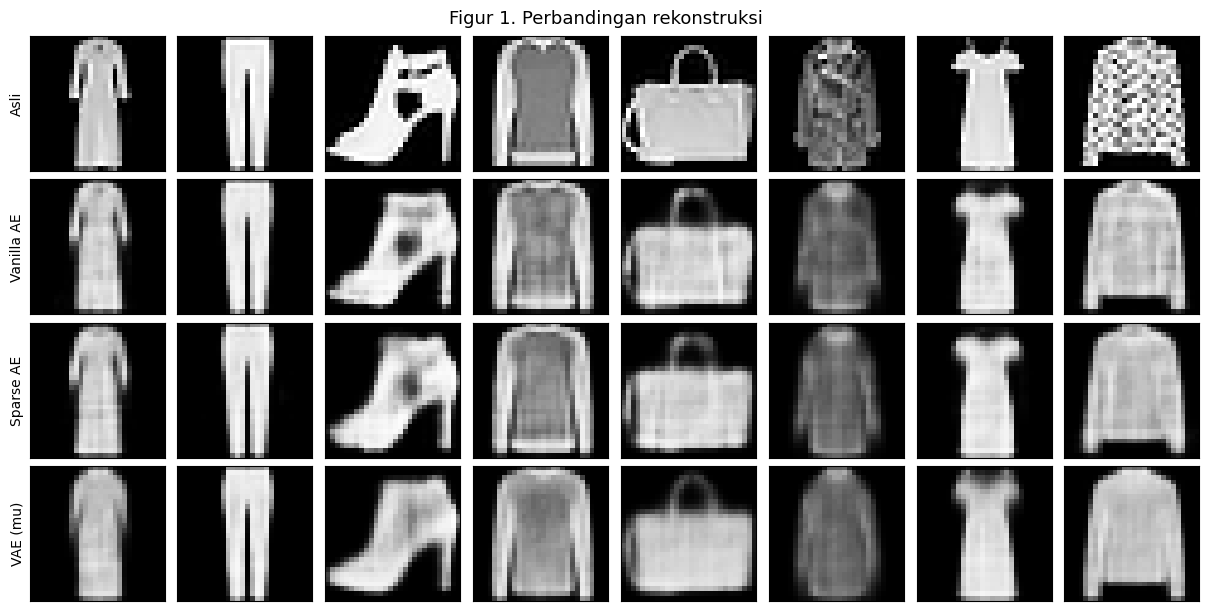

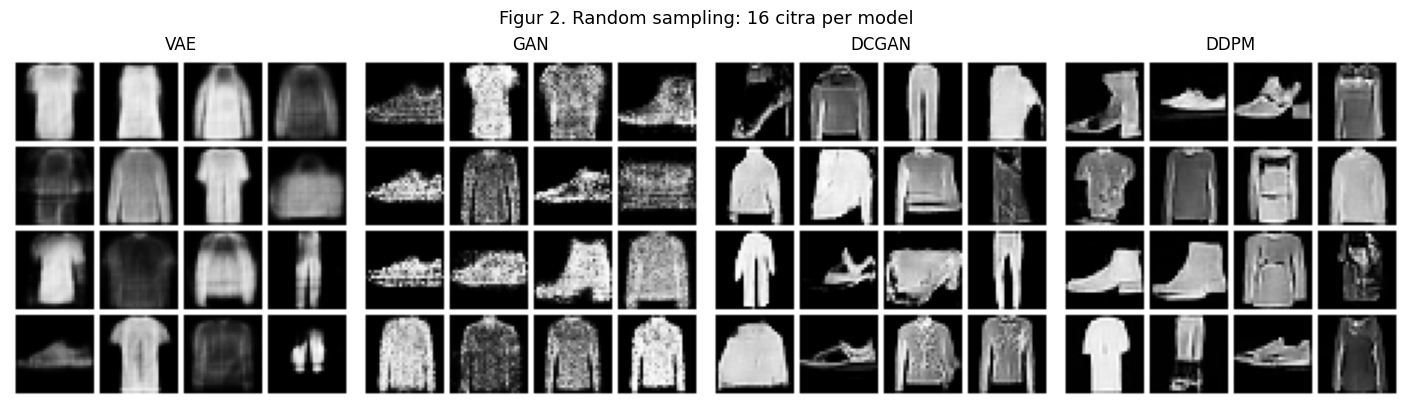

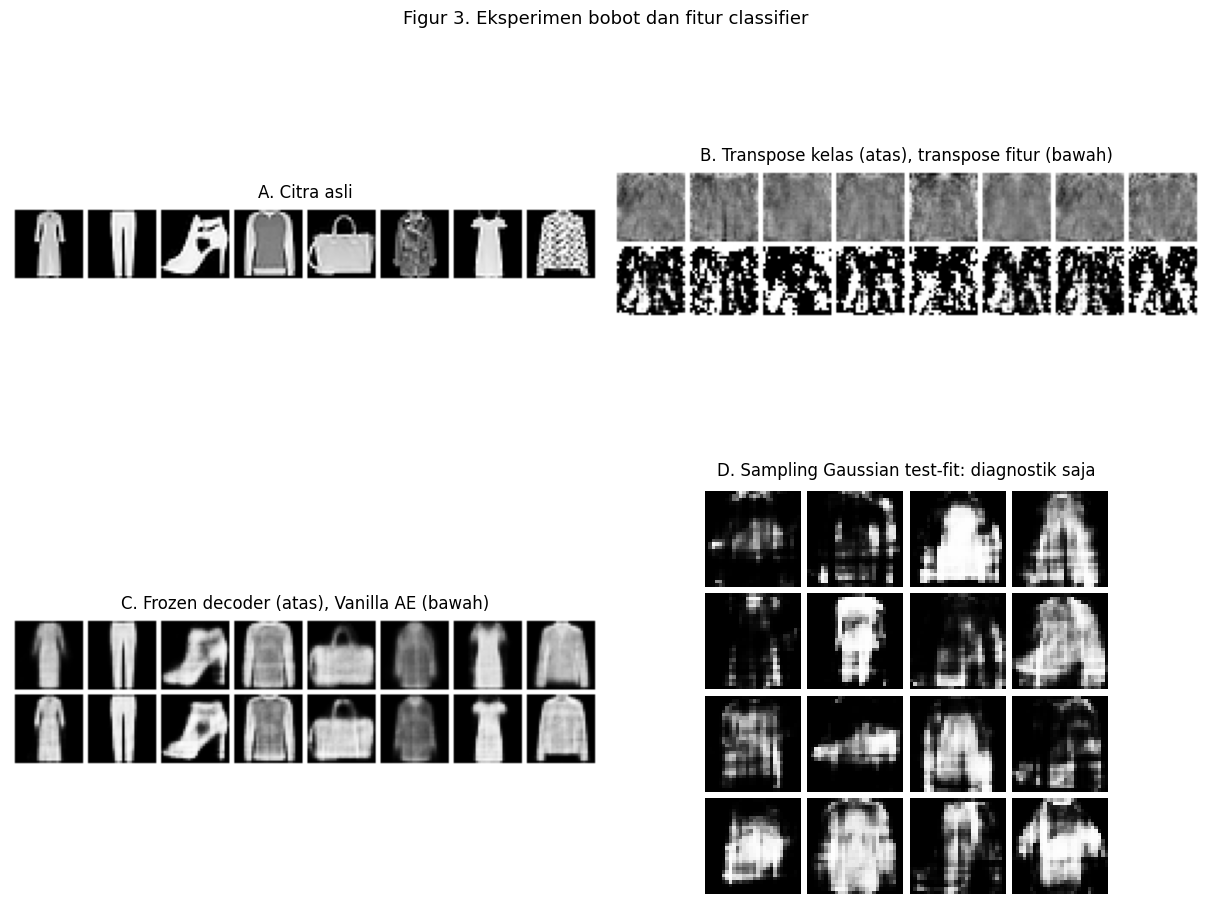

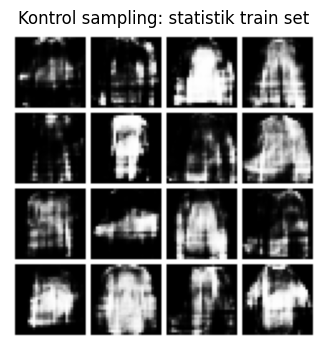

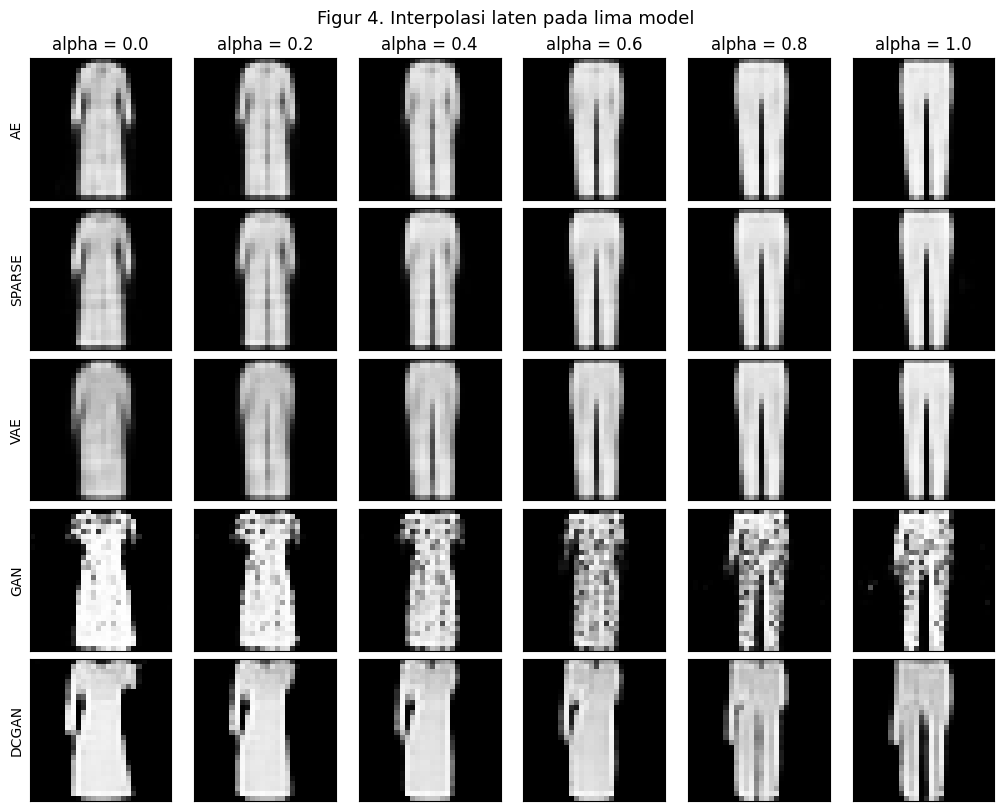

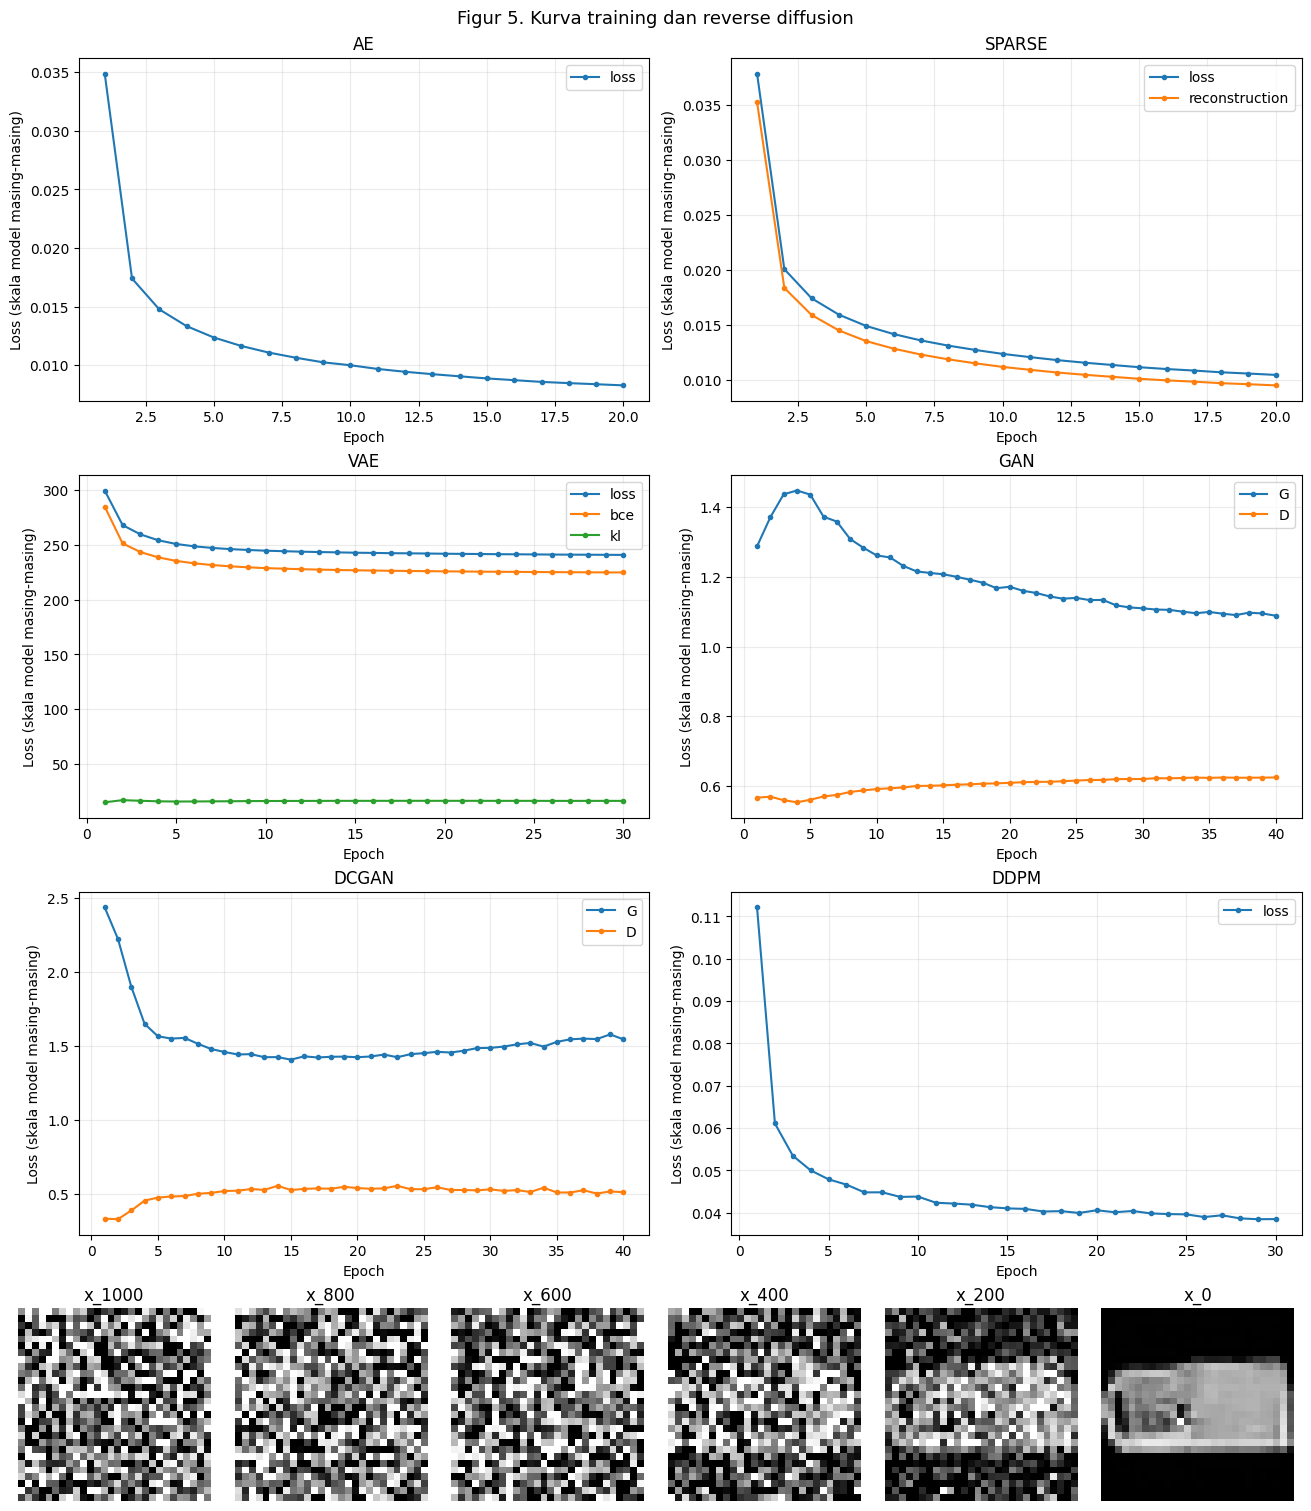

Lima figur tersimpan di /content/drive/MyDrive/GenerativeModelsStudy/full_fashionmnist_seed42_7ffa265f/figures


In [33]:
def finish_figure(fig, number, title):
    status = " | SMOKE TEST: BUKAN HASIL LAPORAN" if PROFILE == "smoke" else ""
    fig.suptitle(f"Figur {number}. {title}{status}", fontsize=13)
    fig.savefig(RUN_DIR / "figures" / f"figure_{number}.png", dpi=240, bbox_inches="tight")
    fig.savefig(RUN_DIR / "figures" / f"figure_{number}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

def show_grid(ax, batch, nrow=4):
    grid = make_grid(batch.detach().cpu(), nrow=nrow, padding=2, pad_value=1)
    ax.imshow(grid.permute(1, 2, 0).clamp(0, 1).numpy())
    ax.axis("off")

display_x = torch.stack([test_set[i][0] for i in range(8)]).to(DEVICE)
display_y = torch.tensor([int(test_set[i][1]) for i in range(8)], device=DEVICE)
models = {}
for name in ["ae", "sparse", "vae", "gan", "dcgan", "ddpm"]:
    m = load_model(name)
    models[name] = m[0] if isinstance(m, tuple) else m

# Figur 1: pasangan citra uji yang sama untuk seluruh rekonstruksi.
with torch.no_grad():
    rows = [display_x, models["ae"](display_x)[0], models["sparse"](display_x)[0],
            models["vae"](display_x, sample=False)[0]]
fig, axes = plt.subplots(4, 8, figsize=(12, 6), constrained_layout=True)
for r, (name, batch) in enumerate(zip(["Asli", "Vanilla AE", "Sparse AE", "VAE (mu)"], rows)):
    for c in range(8):
        axes[r, c].imshow(batch[c, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if c == 0:
            axes[r, c].set_ylabel(name)
finish_figure(fig, 1, "Perbandingan rekonstruksi")

# Figur 2: seed tetap, tidak memilih hanya sampel terbaik.
generated = {}
fig, axes = plt.subplots(1, 4, figsize=(14, 4), constrained_layout=True)
for ax, name in zip(axes, ["vae", "gan", "dcgan", "ddpm"]):
    with isolated_seed(SEED + 404), torch.no_grad():
        generated[name] = generate(name, models[name], 16).cpu()
    show_grid(ax, generated[name])
    ax.set_title(name.upper())
torch.save(generated, RUN_DIR / "samples" / "random_generation.pt")
finish_figure(fig, 2, "Random sampling: 16 citra per model")

# Figur 3: seluruh tahap baseline classifier, termasuk kontrol AE.
with torch.no_grad():
    projected_class = transpose_from_class(display_y)
    projected_latent = transpose_from_features(display_x)
    decoded_frozen = frozen_decoder(classifier.features(display_x))
    decoded_ae = models["ae"](display_x)[0]
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
show_grid(axes[0, 0], display_x, 8)
axes[0, 0].set_title("A. Citra asli")
show_grid(axes[0, 1], torch.cat([projected_class, projected_latent]), 8)
axes[0, 1].set_title("B. Transpose kelas (atas), transpose fitur (bawah)")
show_grid(axes[1, 0], torch.cat([decoded_frozen, decoded_ae]), 8)
axes[1, 0].set_title("C. Frozen decoder (atas), Vanilla AE (bawah)")
show_grid(axes[1, 1], mlp_samples_test, 4)
axes[1, 1].set_title("D. Sampling Gaussian test-fit: diagnostik saja")
finish_figure(fig, 3, "Eksperimen bobot dan fitur classifier")
fig, ax = plt.subplots(figsize=(4, 4))
show_grid(ax, mlp_samples_train)
ax.set_title("Kontrol sampling: statistik train set")
fig.savefig(RUN_DIR / "figures" / "classifier_train_fit_control.png", dpi=240, bbox_inches="tight")
plt.show(); plt.close(fig)

# Figur 4: AE/VAE memakai citra uji; GAN tidak memiliki encoder.
index_a = 0
label_a = int(test_set[index_a][1])
index_b = next(i for i in range(1, len(test_set)) if int(test_set[i][1]) != label_a)
label_b = int(test_set[index_b][1])
pair = torch.stack([test_set[index_a][0], test_set[index_b][0]]).to(DEVICE)
alphas = torch.tensor([0., .2, .4, .6, .8, 1.], device=DEVICE)[:, None]
interpolation_info = {"test_indices": [int(test_idx[index_a]), int(test_idx[index_b])],
                      "target_classes": [label_a, label_b], "gan_endpoints": {}}
fig, axes = plt.subplots(5, 6, figsize=(10, 8), constrained_layout=True)
for r, name in enumerate(["ae", "sparse", "vae", "gan", "dcgan"]):
    model = models[name]
    with torch.no_grad(), isolated_seed(SEED + 505):
        if name in ["ae", "sparse"]:
            endpoints = model.encoder(pair)
        elif name == "vae":
            endpoints = model.encode(pair)[0]
        else:
            # Cari prior samples yang diprediksi classifier sebagai dua kelas target.
            candidates = torch.randn(512, CFG["latent_gan"], device=DEVICE)
            candidate_images = generate(name, model, len(candidates), candidates)
            scores = classifier(candidate_images).softmax(1)
            chosen = []
            for label in [label_a, label_b]:
                valid = torch.where(scores.argmax(1) == label)[0]
                selected = valid[scores[valid, label].argmax()] if len(valid) else scores[:, label].argmax()
                chosen.append(int(selected))
            endpoints = candidates[chosen]
            actual = scores[chosen].argmax(1).tolist()
            interpolation_info["gan_endpoints"][name] = {"predicted_classes": actual,
                "target_classes_found": actual == [label_a, label_b],
                "note": "Class labels are classifier predictions, not guaranteed conditioning."}
            if actual != [label_a, label_b]:
                print(name, "tidak menemukan kedua kelas target; periksa kemungkinan mode dropping.")
        path = (1 - alphas) * endpoints[0] + alphas * endpoints[1]
        decoded = model.decoder(path) if name in ["ae", "sparse", "vae"] else generate(name, model, 6, path)
    for c in range(6):
        axes[r, c].imshow(decoded[c, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(f"alpha = {alphas[c].item():.1f}")
        if c == 0:
            axes[r, c].set_ylabel(name.upper())
(RUN_DIR / "metrics" / "interpolation_protocol.json").write_text(json.dumps(interpolation_info, indent=2))
finish_figure(fig, 4, "Interpolasi laten pada lima model")

# Figur 5: loss antarmodel memiliki satuan berbeda; tidak dibandingkan magnitudonya.
fig = plt.figure(figsize=(13, 15), constrained_layout=True)
layout = fig.add_gridspec(4, 2, height_ratios=[1, 1, 1, .65])
plot_keys = {"ae": ["loss"], "sparse": ["loss", "reconstruction"], "vae": ["loss", "bce", "kl"],
             "gan": ["G", "D"], "dcgan": ["G", "D"], "ddpm": ["loss"]}
for i, name in enumerate(["ae", "sparse", "vae", "gan", "dcgan", "ddpm"]):
    ax = fig.add_subplot(layout[i // 2, i % 2])
    history = json.loads((RUN_DIR / "logs" / f"{name}.json").read_text())
    for key in plot_keys[name]:
        ax.plot([h["epoch"] for h in history], [h[key] for h in history], marker=".", label=key)
    ax.set(title=name.upper(), xlabel="Epoch", ylabel="Loss (skala model masing-masing)")
    ax.grid(alpha=.25); ax.legend()
with isolated_seed(SEED + 606):
    _, states = models["ddpm"].sample(1, trajectory=True)
trajectory_layout = layout[3, :].subgridspec(1, len(states))
for i, (step, image) in enumerate(states.items()):
    ax = fig.add_subplot(trajectory_layout[0, i])
    ax.imshow(((image[0, 0] + 1) / 2).clamp(0, 1), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"x_{step}"); ax.axis("off")
torch.save(states, RUN_DIR / "samples" / "ddpm_trajectory.pt")
finish_figure(fig, 5, "Kurva training dan reverse diffusion")

print("Lima figur tersimpan di", RUN_DIR / "figures")


## 14. Mengisi pembahasan Q1–Q6
Gunakan `Draf_Laporan_Generative_Models.pdf` sebagai kerangka. Ganti setiap `[ISI ...]`
dengan bukti yang dihasilkan notebook, dan ubah penjelasan jika hasil berbeda dari dugaan.

| Pertanyaan | Bukti yang digunakan |
|---|---|
| Q1 | comparison.csv: MSE, PSNR, SSIM, FID; Figur 1–2 |
| Q2 | Figur 1–2; loss AE/VAE vs GAN; aktivasi Sparse AE di logs/sparse.json |
| Q3 | Figur 5; latency batch 64; catatan mode collapse dari Figur 2 |
| Q4 | Figur 4; interpolation_protocol.json |
| Q5 | mlp_experiments.json, classifier.json; Figur 3 |
| Q6 | Gabungkan bukti Q1–Q5; batasi klaim industri pada kemampuan yang benar-benar diuji |

Kurva loss yang rendah tidak menjamin citra baik. Sparse AE tidak selalu lebih buruk pada test reconstruction,
VAE tidak selalu menginterpolasi sempurna, dan DDPM tidak selalu menang pada FID jika anggaran training terbatas.


## 15. Referensi utama
- Kingma & Welling, [Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114).
- Goodfellow et al., [Generative Adversarial Nets](https://arxiv.org/abs/1406.2661).
- Radford et al., [DCGAN](https://arxiv.org/abs/1511.06434).
- Ho, Jain & Abbeel, [Denoising Diffusion Probabilistic Models](https://arxiv.org/abs/2006.11239).
- Mahendran & Vedaldi, [Understanding Deep Image Representations by Inverting Them](https://arxiv.org/abs/1412.0035).
- [PyTorch DCGAN tutorial](https://docs.pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html).
- [TorchMetrics FID documentation](https://lightning.ai/docs/torchmetrics/stable/image/frechet_inception_distance.html).

Konsep dan susunan eksperimen mengikuti materi Sesi 06/07 dan panduan tugas yang diberikan.
